# EDA: Testing the Big West Model's Assumptions

Each section checks one assumption the model makes. Every check ends with **What to look for**,
which tells you how to read the result and what to change in the model if the assumption fails.

| # | Section | Assumption tested |
|---|---|---|
| 1 | Data overview | Data is complete and consistent |
| 2 | Coverage | Entrants have regular-season marks in their event |
| 3 | Scoring | Points table is the same every year |
| 4 | Residuals | Championship marks are normal around the prediction |
| 5 | Offset | Championship offset is consistent across years and ability levels |
| 6 | Predictors | Weighted recent average beats season best / plain average |
| 7 | Conversions | Event-to-event conversions are linear |
| 8 | Indoor vs outdoor | Indoor marks can be used directly |
| 9 | Wind | Wind-aided marks are as predictive as legal ones |
| 10 | Failure | Season failure rate predicts championship failure |
| 11 | Participation | Every entrant competes |
| 12 | Independence | Events are independent for the same athlete |
| 13 | Relays | Relays behave like individual events |
| 14 | HJ / PV | Vertical jumps can be treated as continuous |
| 15 | Fallbacks | Prior-season and imputed athletes are predicted reasonably |

**Requires:** `bigwest_model.py` in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import bigwest_model as bm

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110

REG_PATH = "../data/processed/regular_season.csv"
BW_PATH = "../data/processed/bigwest_2021_2026_results.csv"


===== Fold: calibrate 2021-2022 -> test 2023 =====
conversions fitted: 18 | events skipped (no marks): none
day-form correlation used: 0.21 | blowups in training: 25
entrants using last season: 6 | entrants with no marks (imputed): 3
Brier (scores?)        model 0.112 | base 0.147
Team-event CRPS        model 1.24 | base 1.89   80% coverage 95%
M team totals          CRPS model 8.5 | MAE base 7.2   Spearman model 0.98 | base 0.97
W team totals          CRPS model 4.9 | MAE base 8.8   Spearman model 0.96 | base 0.88


,brier_model,te_crps_model,M_total_crps_model,W_total_crps_model,M_spearman_model,W_spearman_model
current,0.112,1.247,7.051,5.799,0.979,0.954


mark
NT    25
ND     5
Name: count, dtype: int64


## 0. Load and prepare data

In [2]:
CFG = dict(bm.CONFIG)
reg = bm.load_regular(REG_PATH, CFG)
bw = bm.load_bigwest(BW_PATH, CFG)

seasons = sorted(int(x) for x in bw["season"].unique())
cdates = bm.champ_dates(reg, seasons)
bw_events = {g: set(grp["event"]) for g, grp in bw.groupby("gender")}

# For EDA only (descriptive): conversions fit on all seasons. The model itself fits them per fold.
conv_all = bm.fit_conversions(reg, bw_events, CFG)
marks = bm.expand_marks(reg, conv_all, bw_events, CFG)
KEYS = bm.KEYS

def event_group(e):
    if e in bm.RELAYS: return "relay"
    if e in bm.MULTIS: return "multi"
    if e in {"HJ", "PV"}: return "vertical jump"
    if e in {"LJ", "TJ"}: return "horizontal jump"
    if e in {"SP", "DT", "HT", "JT", "WT"}: return "throw"
    if e in {"60", "100", "200", "300", "400", "60H", "100H", "110H", "300H", "400H"}: return "sprint/hurdle"
    return "distance"

bw["group"] = bw["event"].map(event_group)
print("Seasons:", seasons)
print("Reference dates:", {int(s): str(d.date()) for s, d in cdates.items()})

Seasons: [2021, 2022, 2023, 2024, 2025, 2026]
Reference dates: {2021: '2021-05-02', 2022: '2022-05-15', 2023: '2023-05-14', 2024: '2024-05-12', 2025: '2025-05-11', 2026: '2026-05-10'}


## 1. Data overview
**Assumption:** the data is complete and consistent across seasons.

In [3]:
print("Regular-season rows by season")
display(reg.groupby(["season", "gender"]).size().unstack(fill_value=0))

print("Big West entries by season")
display(bw.groupby(["season", "gender"]).size().unstack(fill_value=0))

print("Status counts")
display(pd.concat({"regular season": reg["status"].value_counts(),
                   "Big West": bw["status"].value_counts()}, axis=1).fillna(0).astype(int))

Regular-season rows by season


gender,M,W
season,,
2021,1860,1914
2022,3029,3871
2023,3234,4494
2024,3308,4402
2025,3590,4688
2026,3151,4436


Big West entries by season


gender,M,W
season,,
2021,311,331
2022,334,373
2023,356,383
2024,355,391
2025,426,466
2026,385,468


Status counts


,regular season,Big West
status,,
VALID,40216,4402
FAILED,1591,177
DID_NOT_COMPETE,136,0
MISSING,34,0


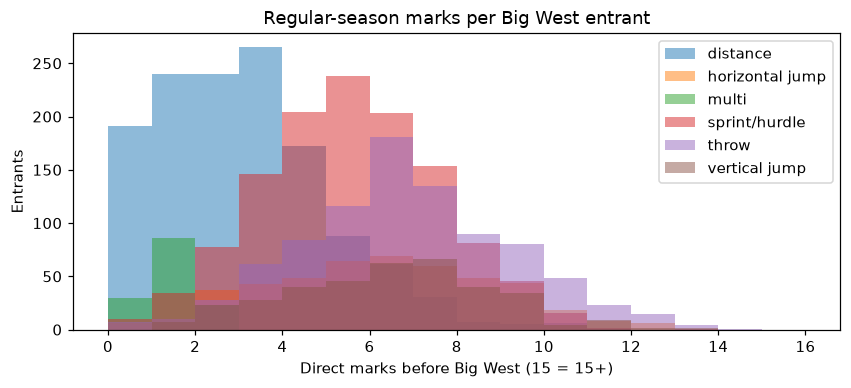

,count,25%,50%,75%
group,,,,
distance,1308.0,1.0,2.0,4.00
horizontal jump,461.0,4.0,6.0,8.00
multi,139.0,1.0,1.0,1.00
sprint/hurdle,1213.0,4.0,5.0,6.00
throw,884.0,5.0,6.0,8.00
vertical jump,364.0,4.0,6.0,7.25


In [4]:
# How many direct marks does each Big West entrant have before the championship?
direct = marks[(marks["kind"] == "direct") & (marks["status"] == "VALID")].copy()
direct = direct[direct["date"] < direct["season"].map(cdates)]
n_marks = direct.groupby(["season"] + KEYS).size().rename("n_marks").reset_index()

entr = bw[~bw["event"].isin(bm.RELAYS)][["season", "group"] + KEYS].drop_duplicates()
entr = entr.merge(n_marks, on=["season"] + KEYS, how="left").fillna({"n_marks": 0})

fig, ax = plt.subplots(figsize=(9, 3.5))
for g, grp in entr.groupby("group"):
    ax.hist(grp["n_marks"].clip(upper=15), bins=range(0, 17), alpha=0.5, label=g)
ax.set_xlabel("Direct marks before Big West (15 = 15+)"); ax.set_ylabel("Entrants"); ax.legend()
ax.set_title("Regular-season marks per Big West entrant")
plt.show()
display(entr.groupby("group")["n_marks"].describe()[["count", "25%", "50%", "75%"]])

**What to look for**
- A season with far fewer rows than the others (likely 2021, COVID) may need to be downweighted.
- A large `MISSING` count means some marks still aren't parsing. Look at examples with
  `reg[reg.status == "MISSING"].mark.value_counts().head(20)`.
- Groups with a median of 1–3 marks rely heavily on shrinkage toward event averages (`k_spread`, `k_fail`).

## 2. Coverage
**Assumption:** most entrants have regular-season marks in the event they enter.

In [5]:
rows = []
for s in seasons:
    if s not in cdates:
        continue
    prof = bm.athlete_profiles(marks[marks["season"] == s], cdates[s], CFG)
    e = bw[(bw["season"] == s)][["season", "group"] + KEYS].drop_duplicates()
    rows.append(e.merge(prof[KEYS + ["n_direct"]], on=KEYS, how="left"))
cov = pd.concat(rows, ignore_index=True)
cov["coverage"] = np.select([cov["n_direct"] > 0, cov["n_direct"].notna()],
                            ["direct marks", "converted only"], "none")
tab = pd.crosstab([cov["gender"], cov["event"]], cov["coverage"], normalize="index").round(2)
display(tab.sort_values("none", ascending=False).head(20))

coverage      converted only  direct marks  none
gender event                                    
M      Dec              0.02          0.74  0.25
W      Hep              0.07          0.81  0.12
M      JT               0.00          0.96  0.04
       TJ               0.00          0.96  0.04
W      10000            0.51          0.46  0.03
       4x400            0.00          0.98  0.02
       JT               0.00          0.98  0.02
       400              0.00          0.98  0.02
M      10000            0.68          0.30  0.02
       100              0.00          0.99  0.01
W      400H             0.00          0.99  0.01
       5000             0.12          0.88  0.01
       SP               0.00          0.99  0.01
       TJ               0.00          0.99  0.01
M      400H             0.00          0.99  0.01
       3000S            0.02          0.97  0.01
       200              0.00          0.99  0.01
       110H             0.00          0.99  0.01
       LJ               0.00          0.99  0.01
       SP               0.00          0.99  0.01

**What to look for**
- Events where many entrants have **converted only** or **none** depend heavily on conversions and fallbacks.
  These are the events where predictions are weakest; report them as a limitation.

Most converted events come from distance events

## 3. Scoring table
**Assumption:** the place-to-points table is the same every year, and ties are rare.

In [6]:
b = bw[bw["points"] > 0].copy()
b["place_n"] = pd.to_numeric(b["place"], errors="coerce")
b["kind"] = np.where(b["event"].isin(bm.RELAYS), "relay", "individual")
display(b.pivot_table(index=["kind", "season"], columns="place_n", values="points",
                      aggfunc=lambda x: x.mode().iloc[0]))

# Ties: total points in an event should be 39 (10+8+6+5+4+3+2+1) unless places are tied or unfilled
tot = bw.groupby(["season", "gender", "event"])["points"].sum()
print("Events where total points != 39:")
display(tot[tot.round(1) != 39].reset_index().head(20))

place_n             1.0  2.0  3.0  4.0  5.0  6.0  7.0  8.0
kind       season                                         
individual 2021    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2022    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2023    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2024    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2025    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2026    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
relay      2021    10.0  8.0  6.0  5.0  4.0  3.0  2.0  NaN
           2022    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2023    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2024    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2025    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0
           2026    10.0  8.0  6.0  5.0  4.0  3.0  2.0  1.0

Events where total points != 39:


,season,gender,event,points
0,2021,M,110H,38.0
1,2021,M,200,38.0
2,2021,M,400,38.0
3,2021,M,4x100,38.0
4,2021,M,4x400,38.0
5,2021,W,4x100,38.0
6,2021,W,4x400,36.0
7,2022,M,400H,38.0
8,2022,M,4x100,38.0
9,2022,W,100H,38.0


**What to look for**
- Any season whose row differs from 10-8-6-5-4-3-2-1 means the model's single points table is wrong for that year.
- Totals other than 39 mean tied places (points split) or fewer than 8 scorers. The model never produces ties.

## 4. Residuals: are championship marks normal around the prediction?
**Assumption:** a Big West mark = athlete's weighted mean `mu` + noise drawn from a normal distribution with spread `sd`
(on the p scale). This is the core simulation assumption.

- `res` = p_actual − mu: how much better (+) or worse (−) than season form, as a fraction (0.01 ≈ 1%)
- `z` = res / sd: the residual in units of the athlete's predicted spread. If the model's spreads are right, `z` has sd ≈ 1.

4352 athlete-events with both a profile and a valid Big West mark


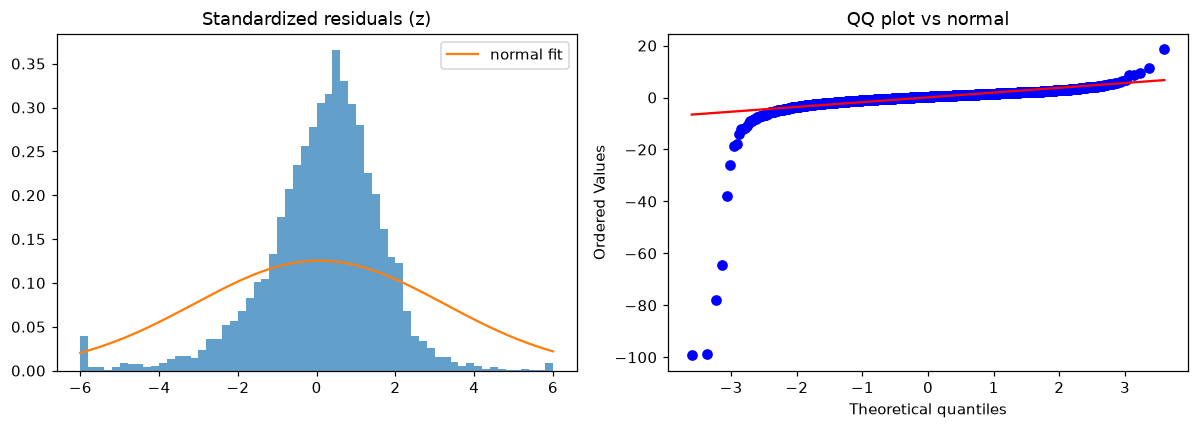

mean z: 0.066   sd z: 3.181   skew: -19.857   excess kurtosis: 557.895


In [7]:
recs = []
for s in seasons:
    if s not in cdates:
        continue
    prof = bm.athlete_profiles(marks[marks["season"] == s], cdates[s], CFG)
    act = bw[(bw["season"] == s) & (bw["status"] == "VALID")][KEYS + ["p", "group", "place"]]
    recs.append(act.merge(prof, on=KEYS).assign(season=s))
res = pd.concat(recs, ignore_index=True)
res["res"] = res["p"] - res["mu"]
res["z"] = res["res"] / res["sd"]
print(f"{len(res)} athlete-events with both a profile and a valid Big West mark")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(res["z"].clip(-6, 6), bins=60, density=True, alpha=0.7)
x = np.linspace(-6, 6, 200)
ax[0].plot(x, stats.norm.pdf(x, res["z"].mean(), res["z"].std()), label="normal fit")
ax[0].set_title("Standardized residuals (z)"); ax[0].legend()
stats.probplot(res["z"].dropna(), plot=ax[1]); ax[1].set_title("QQ plot vs normal")
plt.tight_layout(); plt.show()

print(f"mean z: {res['z'].mean():.3f}   sd z: {res['z'].std():.3f}   "
      f"skew: {stats.skew(res['z']):.3f}   excess kurtosis: {stats.kurtosis(res['z']):.3f}")

In [8]:
by_group = res.groupby("group").agg(
    n=("z", "size"),
    offset_pct=("res", lambda r: 100 * r.mean()),
    z_sd=("z", "std"),
    z_skew=("z", lambda z: stats.skew(z)),
    within_1sd=("z", lambda z: (z.abs() <= 1).mean()),
).round(3)
print("Expected within_1sd for a normal: 0.683")
display(by_group)

by_event = res.groupby(["gender", "event"]).agg(
    n=("z", "size"), offset_pct=("res", lambda r: 100 * r.mean()), z_sd=("z", "std")).round(3)
display(by_event.sort_values("z_sd", ascending=False))

Expected within_1sd for a normal: 0.683


,n,offset_pct,z_sd,z_skew,within_1sd
group,,,,,
distance,1252,-1.208,1.569,-1.155,0.563
horizontal jump,428,1.370,1.286,-0.574,0.600
multi,115,4.506,2.856,2.627,0.557
relay,200,1.525,1.305,-1.867,0.560
sprint/hurdle,1179,0.371,5.439,-14.593,0.528
throw,843,1.983,1.701,-5.554,0.537
vertical jump,335,0.983,1.186,-0.230,0.591


n  offset_pct    z_sd
gender event                         
M      100    154      -0.978  10.794
       400    126      -0.895   8.922
       200    137       0.119   5.771
W      Hep     76       4.407   3.116
       JT      90       2.696   3.014
M      110H    80       0.791   2.720
       400H    72       1.140   2.622
       Dec     39       4.699   2.298
       JT      80       2.276   2.069
W      1500   138      -1.234   2.047
M      800    104      -0.445   1.841
       3000S   96       0.342   1.760
W      4x100   50       0.501   1.731
M      DT     100       1.345   1.656
W      DT     118       2.182   1.635
M      1500   113      -0.515   1.602
W      200    145       0.764   1.576
M      5000   186      -2.827   1.432
       4x100   44       0.488   1.429
       LJ     130       1.856   1.403
W      800    122      -0.192   1.396
M      HJ      77       0.640   1.326
       HT      98       0.930   1.290
W      TJ      83       0.978   1.285
M      TJ      87       1.457   1.271
       SP     104       1.794   1.259
W      3000S   96      -0.081   1.252
       SP     133       1.985   1.247
       400    123       0.367   1.232
       HJ     109       0.578   1.229
       100H   107       1.709   1.186
       5000   189      -1.794   1.182
       400H    92       0.880   1.178
       HT     120       2.613   1.168
M      10000   91      -2.449   1.166
W      LJ     128       1.071   1.161
       PV      83       1.264   1.116
       10000  117      -1.295   1.059
M      4x400   53       2.156   0.996
       PV      66       1.696   0.988
W      100    143       0.833   0.930
       4x400   53       2.720   0.753

**What to look for**
- **z sd well below 1:** predicted spreads are too wide. This explains coverage above 80%; lower `k_spread`
  or cap the calibration `scale`.
- **z sd well above 1:** spreads are too narrow, so the model is overconfident.
- **Negative skew / left QQ tail bending down:** bad days are worse than good days are good.
  A skewed distribution would fit better than the normal.
- **Excess kurtosis > 0 / both QQ tails bending:** more surprise results than a normal predicts
  (consider a Student's t).
- **offset_pct** is the average gain (+) or loss (−) vs season form at Big West. Calibration learns this per event.

## 5. Championship offset: consistent across years and ability levels?
**Assumption:** one offset per event, the same every year and for every athlete in the event.

In [9]:
display((100 * res.pivot_table(index="group", columns="season", values="res", aggfunc="mean")).round(2))

# Do top athletes peak for conference more than others?
res["mu_rank_pct"] = res.groupby(["season", "gender", "event"])["mu"].rank(pct=True, ascending=False)
res["ability"] = pd.cut(res["mu_rank_pct"], [0, 0.25, 0.5, 0.75, 1.0],
                        labels=["top 25%", "25-50%", "50-75%", "bottom 25%"])
display((100 * res.groupby("ability", observed=True)["res"].agg(["mean", "std", "size"])).round(2)
        .rename(columns={"mean": "offset_pct", "std": "res_sd_pct", "size": "n_x100"}))

season,2021,2022,2023,2024,2025,2026
group,,,,,,
distance,-0.45,-1.49,-1.32,-0.99,-1.14,-1.71
horizontal jump,1.84,1.19,1.42,1.89,1.02,1.06
multi,9.12,0.28,4.53,5.79,4.85,5.23
relay,1.55,1.33,2.14,1.33,1.43,1.40
sprint/hurdle,0.20,0.04,0.20,-0.01,0.54,0.99
throw,1.89,0.53,3.23,0.67,2.52,2.63
vertical jump,0.50,0.60,0.84,1.23,1.51,1.15


,offset_pct,res_sd_pct,n_x100
ability,,,
top 25%,0.04,6.26,99000
25-50%,0.41,4.16,111900
50-75%,0.37,4.81,106000
bottom 25%,1.22,5.06,118300


**What to look for**
- Offsets that flip sign between seasons are mostly noise (or weather) and should be shrunk more (`cal_prior_n`).
- If top athletes have a clearly different offset than the bottom of the field, a single per-event offset is
  too simple. The offset could depend on the athlete's rank in the field.
- (`n_x100` is the count ×100 from the percentage scaling; divide by 100.)

## 6. Which regular-season summary predicts Big West best?
**Assumption:** a recency-weighted average (half-life 45 days) beats the season best or a plain average.

Compared on direct marks only. "Bias-corrected" subtracts each event's average offset, so a summary isn't
penalized just for being systematically high (season best always is).

In [10]:
d = direct.sort_values("date")
summ = d.groupby(["season"] + KEYS).agg(best=("p", "max"), mean=("p", "mean"),
                                        last3=("p", lambda x: x.tail(3).mean()),
                                        n=("p", "size")).reset_index()
act = bw[bw["status"] == "VALID"][["season"] + KEYS + ["p", "group"]]
cmp_ = summ.merge(act, on=["season"] + KEYS)

for hl in [15, 30, 45, 90, 10_000]:
    cfg = {**CFG, "half_life_days": hl}
    w = pd.concat([bm.athlete_profiles(direct[direct["season"] == s], cdates[s], cfg)
                   .assign(season=s)[["season"] + KEYS + ["mu"]] for s in seasons if s in cdates])
    name = f"weighted hl={hl}" if hl < 10_000 else "weighted hl=inf"
    cmp_ = cmp_.merge(w.rename(columns={"mu": name}), on=["season"] + KEYS, how="left")

preds = [c for c in cmp_.columns if c in ("best", "mean", "last3") or c.startswith("weighted")]
out = {}
for c in preds:
    err = cmp_["p"] - cmp_[c]
    err_bc = err - err.groupby([cmp_["gender"], cmp_["event"]]).transform("mean")
    out[c] = {"MAE %": 100 * err.abs().mean(), "bias-corrected MAE %": 100 * err_bc.abs().mean()}
display(pd.DataFrame(out).T.round(3).sort_values("bias-corrected MAE %"))

,MAE %,bias-corrected MAE %
best,2.814,2.438
weighted hl=45,2.724,2.446
weighted hl=30,2.703,2.447
weighted hl=90,2.756,2.457
mean,2.802,2.477
weighted hl=inf,2.801,2.477
weighted hl=15,2.692,2.482
last3,2.705,2.533


**What to look for**
- The row with the lowest **bias-corrected MAE** is the best predictor of championship form.
- If a short half-life (15–30) wins, recent form matters more than the model assumes; lower `half_life_days`.
  If `hl=inf` (no recency weighting) wins, recency weighting isn't helping.
- If `best` wins, athletes tend to reproduce peak marks at Big West, and `mu` should lean toward the best.

## 7. Conversions: are they linear?
**Assumption:** related events convert with a straight line on the p scale (e.g. 60 → 100).

Fitted conversions (all seasons; EDA only)


a       b  resid_sd      n
gender source target                                 
W      1500   5000   -1.8743  0.9000    0.0275  246.0
M      1500   5000   -3.1990  0.6561    0.0265  231.0
W      60     100    -1.0666  0.6951    0.0212  186.0
       3000   1500   -0.8649  0.7442    0.0303  180.0
              5000   -1.0134  0.9249    0.0221  176.0
       Mile   1500   -2.0515  0.6247    0.0248  174.0
       60H    100H   -0.7620  0.8725    0.0350  162.0
M      3000   1500   -2.3083  0.5051    0.0255  133.0
       Mile   1500   -1.6130  0.6926    0.0203  122.0
       3000   5000   -2.5810  0.6726    0.0216  119.0
       60     100    -1.4665  0.4650    0.0270  113.0
W      WT     HT      1.8576  0.7448    0.0913  113.0
M      5000   3000S  -0.6710  0.8330    0.0293   69.0
W      5000   3000S  -0.4092  0.8736    0.0253   64.0
              10000  -0.2685  1.0677    0.0195   61.0
       10000  5000   -0.9312  0.7825    0.0167   61.0
M      60H    110H   -0.4350  1.0666    0.0215   53.0
W      Pent   Hep     3.5812  0.5975    0.0927   52.0
M      WT     HT      1.5244  0.8806    0.0654   51.0
W      3000   3000S  -2.0592  0.6901    0.0295   48.0
M      10000  5000   -0.8915  0.7830    0.0210   39.0
       5000   10000  -1.8009  0.8432    0.0218   39.0
       3000   3000S  -2.6468  0.5894    0.0257   37.0
W      600    800    -2.5025  0.5230    0.0286   33.0
              400    -2.4158  0.3603    0.0314   21.0
       2000S  3000S  -2.5814  0.6433    0.0226   17.0
M      1000   1500    0.5521  1.2029    0.0484   17.0
       600    800    -1.7065  0.6867    0.0252   14.0
W      1000   800    -2.8049  0.4041    0.0240   13.0
M      Hep    Dec     4.0392  0.5615    0.1245   13.0
W      1000   1500   -1.4068  0.8137    0.0120   11.0

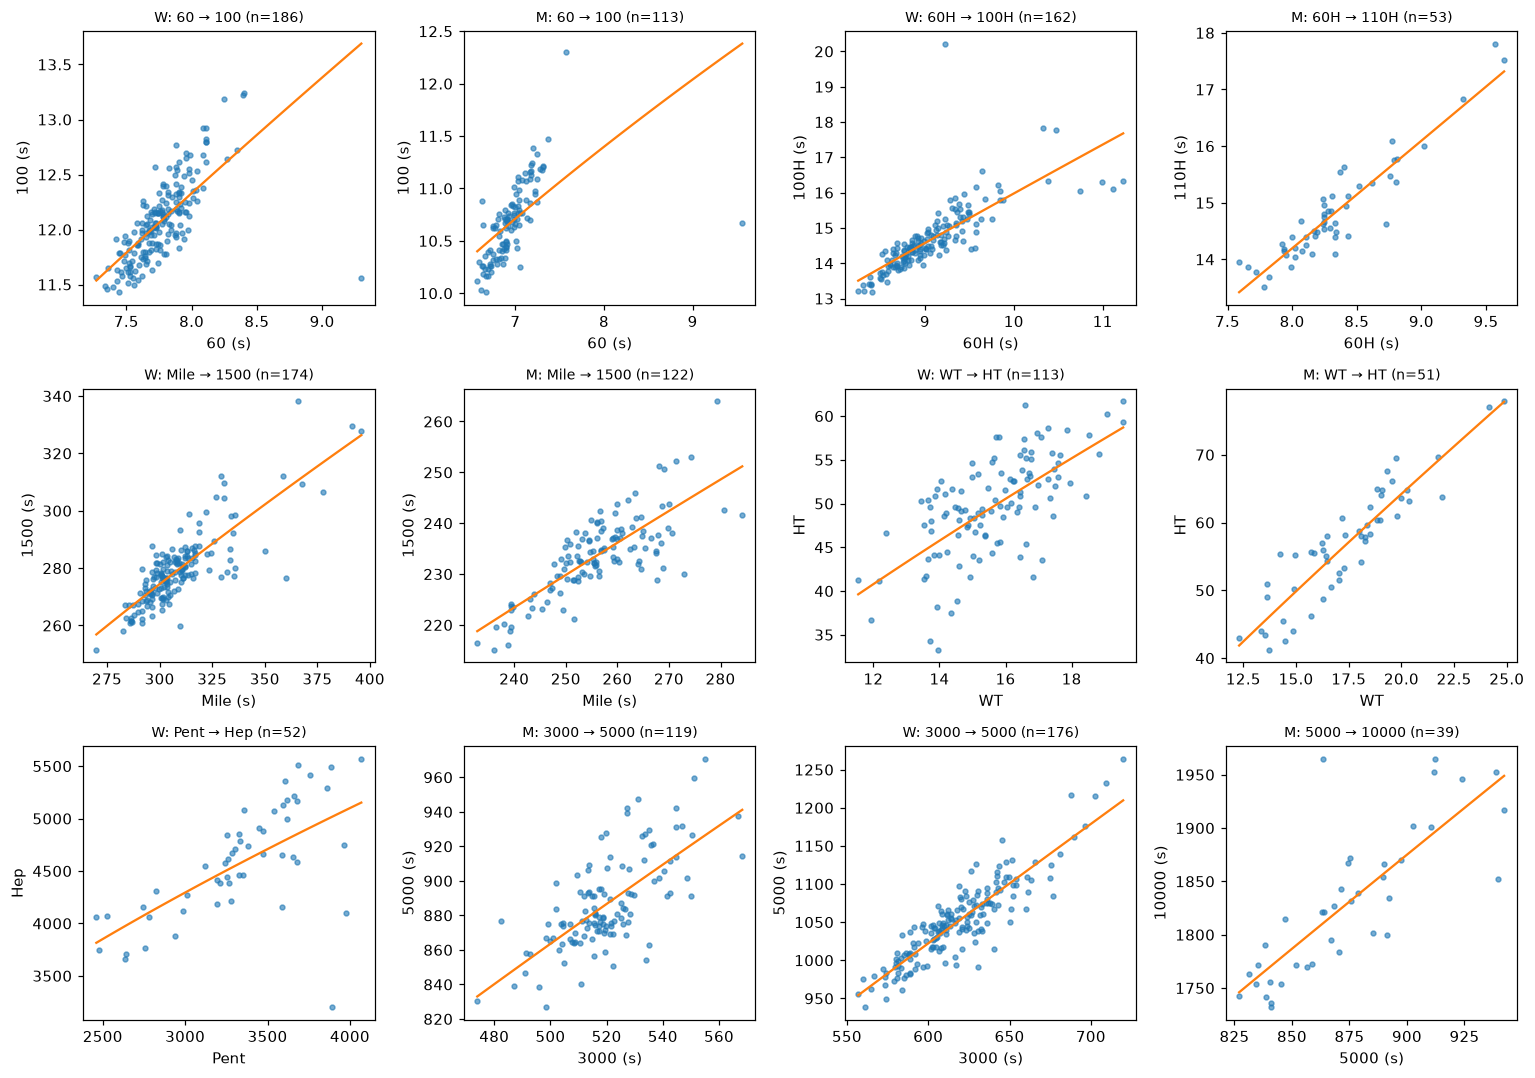

In [11]:
print("Fitted conversions (all seasons; EDA only)")
display(pd.DataFrame(conv_all).T.rename_axis(["gender", "source", "target"]).round(4)
        .sort_values("n", ascending=False))

sb = bm.season_bests(reg)
pairs = [("W", "60", "100"), ("M", "60", "100"), ("W", "60H", "100H"), ("M", "60H", "110H"),
         ("W", "Mile", "1500"), ("M", "Mile", "1500"), ("W", "WT", "HT"), ("M", "WT", "HT"),
         ("W", "Pent", "Hep"), ("M", "3000", "5000"), ("W", "3000", "5000"), ("M", "5000", "10000")]

def natural(p, ev):
    return np.exp(p) if bm.higher_is_better(ev) else np.exp(-p)

shown = [(g, a, b_) for g, a, b_ in pairs
         if g in sb.index.get_level_values("gender") and {a, b_} <= set(sb.columns)
         and len(sb.xs(g, level="gender")[[a, b_]].dropna()) >= 5]
cols = 4
rows_ = int(np.ceil(len(shown) / cols)) or 1
fig, axes = plt.subplots(rows_, cols, figsize=(14, 3.3 * rows_), squeeze=False)
for ax, (g, a, b_) in zip(axes.flat, shown):
    both = sb.xs(g, level="gender")[[a, b_]].dropna()
    ax.scatter(natural(both[a], a), natural(both[b_], b_), s=10, alpha=0.6)
    slope, icpt = np.polyfit(both[a], both[b_], 1)
    xs = np.linspace(both[a].min(), both[a].max(), 50)
    ax.plot(natural(xs, a), natural(icpt + slope * xs, b_), color="C1")
    ax.set_title(f"{g}: {a} → {b_} (n={len(both)})", fontsize=9)
    ax.set_xlabel(a + (" (s)" if not bm.higher_is_better(a) else "")); ax.set_ylabel(b_ + (" (s)" if not bm.higher_is_better(b_) else ""))
for ax in list(axes.flat)[len(shown):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**What to look for**
- Points should follow the line. A clear curve means a linear conversion is wrong at the extremes.
- Big scatter (large `resid_sd`) means converted marks are weak evidence. Consider lowering `conv_weight`
  for that pair.
- Outliers far from the line may be data errors (wrong event code, wrong units).

## 8. Indoor vs outdoor
**Assumption:** indoor marks in the same event (200, 400, 800, field events) can be used directly.

Your data has no indoor flag, so **January–February** is used as a proxy for indoor.
Note that outdoor marks also benefit from later-season fitness, so part of any gap is training, not the venue.

In [12]:
v = reg[reg["status"] == "VALID"].copy()
v["venue"] = np.where(v["date"].dt.month.isin([1, 2]), "indoor (Jan-Feb)", "outdoor (Mar-May)")
evs = ["200", "400", "800", "SP", "LJ", "TJ", "HJ", "PV"]
sbv = (v[v["event"].isin(evs)].groupby(["season", "gender", "athlete_id", "event", "venue"])["p"].max()
       .unstack("venue").dropna())
sbv["outdoor_better_pct"] = 100 * (sbv["outdoor (Mar-May)"] - sbv["indoor (Jan-Feb)"])
display(sbv.groupby("event")["outdoor_better_pct"].agg(["median", "mean", "size"]).round(2))

,median,mean,size
event,,,
200,1.43,1.63,395
400,1.44,1.44,220
800,2.35,2.77,189
HJ,0.94,1.16,187
LJ,3.33,3.47,288
PV,2.64,2.66,104
SP,3.39,3.49,264
TJ,1.78,2.04,134


**What to look for**
- A consistent positive gap in the 200/400 (often 1%+) means indoor marks understate outdoor ability.
  Treat those as converted marks (with an offset) instead of direct ones.
- Compare against field events, where the venue matters less. That gap is mostly the training effect,
  so the *extra* gap in the 200/400 is the venue effect.

## 9. Wind
**Assumption:** wind-aided marks (tailwind > 2.0 m/s) predict Big West as well as legal ones.

In [13]:
wv = direct[direct["event"].isin(bm.WIND_EVENTS)].merge(
    reg[["athlete_id", "date", "event", "p", "wind"]].drop_duplicates(["athlete_id", "date", "event", "p"]),
    on=["athlete_id", "date", "event", "p"], how="left")
wv["wind"] = pd.to_numeric(wv["wind"], errors="coerce")
wv["aided"] = wv["wind"] > 2.0
print("Share of marks wind-aided, by event:")
display(wv.groupby("event")["aided"].mean().round(3))

g = wv.groupby(["season"] + KEYS)
w_cmp = pd.DataFrame({"all_marks": g["p"].mean(),
                      "legal_only": wv[~wv["aided"]].groupby(["season"] + KEYS)["p"].mean()}).dropna()
w_cmp = w_cmp.reset_index().merge(act, on=["season"] + KEYS)
for c in ["all_marks", "legal_only"]:
    e = w_cmp["p"] - w_cmp[c]
    e = e - e.groupby(w_cmp["event"]).transform("mean")
    print(f"{c:>11}: bias-corrected MAE {100 * e.abs().mean():.3f}%   (n={len(e)})")

Share of marks wind-aided, by event:


event
100     0.142
100H    0.128
110H    0.162
200     0.101
LJ      0.082
TJ      0.080
Name: aided, dtype: float64

  all_marks: bias-corrected MAE 1.968%   (n=1187)
 legal_only: bias-corrected MAE 2.014%   (n=1187)


**What to look for**
- If `legal_only` has a clearly lower error, wind-aided marks mislead; set `drop_wind_aided=True`
  (or downweight them).
- If the two are about equal, keeping aided marks is fine and keeps more data.

## 10. Failure rate
**Assumption:** an athlete's regular-season failure rate (foul out, DNF, DQ, NH) predicts failure at Big West.

In [14]:
dm = marks[(marks["kind"] == "direct") & marks["status"].isin(["VALID", "FAILED"])].copy()
dm = dm[dm["date"] < dm["season"].map(cdates)]
fr = (dm.assign(f=dm["status"].eq("FAILED")).groupby(["season"] + KEYS)["f"]
      .agg(season_fail_rate="mean", n_entries="size").reset_index())
bwf = bw[bw["status"].isin(["VALID", "FAILED"]) & ~bw["event"].isin(bm.RELAYS)][["season", "group"] + KEYS + ["status"]]
bwf["champ_failed"] = bwf["status"].eq("FAILED")
ff = bwf.merge(fr, on=["season"] + KEYS, how="left")
ff["season_bin"] = pd.cut(ff["season_fail_rate"].fillna(-1), [-1.5, -0.5, 0, 0.2, 1.0],
                          labels=["no history", "0%", "0-20%", ">20%"])
display(ff.groupby("season_bin", observed=True)["champ_failed"].agg(["mean", "size"]).round(3))

print("Failure rate by group: season vs Big West")
season_rate = dm.assign(f=dm["status"].eq("FAILED"), group=dm["event"].map(event_group)).groupby("group")["f"].mean()
display(pd.DataFrame({"season": season_rate, "Big West": ff.groupby("group")["champ_failed"].mean()}).round(3))

,mean,size
season_bin,,
no history,0.103,233
0%,0.026,3567
0-20%,0.078,334
>20%,0.111,235


Failure rate by group: season vs Big West


,season,Big West
group,,
distance,0.036,0.037
horizontal jump,0.049,0.061
multi,0.020,0.014
relay,0.060,NaN
sprint/hurdle,0.008,0.021
throw,0.042,0.040
vertical jump,0.104,0.080


**What to look for**
- Championship failure should rise with the season failure rate. If it's flat, athlete history doesn't help;
  increase `k_fail` so `p_fail` relies more on event rates.
- If Big West failure is much higher (or lower) than the season rate for a group, add a championship
  adjustment to `p_fail`.

## 11. Participation
**Assumption:** every Big West entrant starts their event.

In [15]:
display(pd.crosstab(bw["season"], bw["status"]))
dns = bw[bw["status"] == "DID_NOT_COMPETE"]
print(f"DNS / scratches: {len(dns)} of {len(bw)} entries ({100 * len(dns) / max(len(bw), 1):.1f}%)")
display(dns.groupby("group").size())

status,FAILED,VALID
season,,
2021,16,626
2022,36,671
2023,17,722
2024,27,719
2025,43,849
2026,38,815


DNS / scratches: 0 of 4579 entries (0.0%)


Series([], dtype: int64)

**What to look for**
- **0 DNS rows** may mean the file lists only athletes who competed. In that case the model knows who
  showed up, which is mild leakage; state it as a limitation.
- If DNS is common in some events (e.g. distance doubles), add a scratch probability to the simulation.

## 12. Independence across events
**Assumption:** an athlete's performances in different events at the same Big West are independent
(no shared "good day", no fatigue from doubling).

In [16]:
ind = res[~res["event"].isin(bm.RELAYS)]
multi = ind.groupby(["season", "athlete_id"]).filter(lambda x: len(x) >= 2)
pairs_z = []
for _, grp in multi.groupby(["season", "athlete_id"]):
    z = grp["z"].to_numpy()
    for i in range(len(z)):
        for j in range(i + 1, len(z)):
            pairs_z.append((z[i], z[j]))
pairs_z = np.array(pairs_z)
if len(pairs_z) > 2:
    r, pval = stats.pearsonr(pairs_z[:, 0], pairs_z[:, 1])
    print(f"Correlation of residuals between an athlete's events: r = {r:.3f} (p = {pval:.3f}, {len(pairs_z)} pairs)")
else:
    print("Not enough athletes with 2+ individual events to test.")

n_ev = ind.groupby(["season", "athlete_id"])["event"].transform("size")
display((100 * ind.groupby(np.where(n_ev >= 2, "2+ events", "1 event"))["res"].agg(["mean", "std"]))
        .round(3).rename(columns={"mean": "offset_pct", "std": "res_sd_pct"}))

Correlation of residuals between an athlete's events: r = 0.468 (p = 0.000, 1566 pairs)


,offset_pct,res_sd_pct
1 event,0.488,5.836
2+ events,0.489,4.774


**What to look for**
- **r clearly above 0:** good and bad days are shared across events. Independent draws understate the spread of
  team totals; add a shared "day form" term per athlete.
- **Multi-event athletes with a lower offset:** fatigue from doubling. Add a penalty for athletes entered in
  several events.

## 13. Relays
**Assumption:** a team's relay behaves like an individual athlete (season marks predict Big West).

In [17]:
res["kind"] = np.where(res["event"].isin(bm.RELAYS), "relay", "individual")
display((100 * res.groupby(["kind", "group"])["res"].agg(["mean", "std", "size"])).round(3)
        .rename(columns={"mean": "offset_pct", "std": "res_sd_pct", "size": "n_x100"}))
display(res.groupby("kind")["z"].agg(["std", "size"]).round(3))

offset_pct  res_sd_pct  n_x100
kind       group                                          
individual distance             -1.208       2.587  125200
           horizontal jump       1.370       3.904   42800
           multi                 4.506       8.309   11500
           sprint/hurdle         0.371       5.697  117900
           throw                 1.983       7.007   84300
           vertical jump         0.983       2.807   33500
relay      relay                 1.525       1.803   20000

,std,size
kind,,
individual,3.241,4152
relay,1.305,200


**What to look for**
- Relays with a much larger `res_sd_pct` than sprints means lineup changes make relays less predictable;
  their spread should be inflated.
- A relay `z` sd far from the individual one means calibration should be separate for relays (it already is
  per event, so check the relay events' values).

## 14. High jump and pole vault
**Assumption:** vertical jumps can be simulated as continuous marks (no ties).

In [18]:
vj = bw[bw["event"].isin(["HJ", "PV"]) & (bw["status"] == "VALID")].copy()
vj["place_n"] = pd.to_numeric(vj["place"], errors="coerce")
tied_marks = vj.groupby(["season", "gender", "event", "value"]).size()
print(f"Share of HJ/PV athletes sharing their exact mark with another: "
      f"{(tied_marks[tied_marks > 1].sum() / max(len(vj), 1)):.1%}")
tied_places = vj.groupby(["season", "gender", "event", "place_n"]).size()
print(f"Share of HJ/PV athletes in a tied place: {(tied_places[tied_places > 1].sum() / max(len(vj), 1)):.1%}")
display(res[res["event"].isin(["HJ", "PV"])].groupby("event")["z"].agg(["std", "size"]).round(3))

Share of HJ/PV athletes sharing their exact mark with another: 80.9%
Share of HJ/PV athletes in a tied place: 32.8%


,std,size
event,,
HJ,1.267,186
PV,1.067,149


**What to look for**
- Many shared marks but few tied places: countback breaks most ties, so the continuous approximation is fine
  for places.
- Many tied places: points are split in reality but never in the simulation. Round simulated heights to bar
  increments and split points on ties.

## 15. Fallbacks
**Assumption:** prior-season profiles and the imputed prior (20th percentile of the field) are reasonable.
Runs the validation folds with fewer simulations for speed.

In [19]:
cfg_fast = {**CFG, "n_sims": 3000}
fold_ath = []
for cal_seasons, test in bm.FOLDS:
    if test in seasons and all(s in cdates for s in cal_seasons + [test]):
        r = bm.run_fold(reg, bw, cal_seasons, test, cdates, bw_events, cfg_fast, verbose=False)
        fold_ath.append(r["athletes"].assign(test=test))
fa = pd.concat(fold_ath, ignore_index=True)
fa["scored"] = fa["actual_pts"] > 0
display(fa.groupby("source").agg(n=("scored", "size"),
                                 predicted_p_score=("p_score", "mean"), actual_scored=("scored", "mean"),
                                 predicted_pts=("exp_pts", "mean"), actual_pts=("actual_pts", "mean")).round(3))

,n,predicted_p_score,actual_scored,predicted_pts,actual_pts
source,,,,,
current,2353,0.422,0.424,2.068,2.070
none,12,0.152,0.333,0.527,1.083
prior_season,12,0.654,0.583,2.892,2.167


**What to look for**
- For each source, `predicted_p_score` should be close to `actual_scored`, and `predicted_pts` close to `actual_pts`.
- **`none` (imputed) actual > predicted:** the 20th-percentile prior is too pessimistic; raise it.
- **`prior_season` far off:** the 1.5× spread inflation (`PRIOR_SD_INFLATE`) or year-to-year change needs adjusting.

## Summary of findings
Fill in after running:

| Check | Result | Model change |
|---|---|---|
| 4. Residual spread (z sd) | z sd 3.18 overall; 1.43 without the 62 pull-ups|Pull-ups count as failures; robust spread scale|
| 4. Skew / tails | Extreme left tail from pull-ups| Same as above|
| 5. Offset stability | Same direction every year; bottom 25% +1.2% vs top 0.04%| To do: shrink mu toward the field average|
| 6. Best predictor / half-life | Season best ≈ weighted (hl 30–45)| None|
| 7. Conversions | Linear; a few bad points| To do: robust fit|
| 8. Indoor gap | No extra sprint gap beyond normal progression| None|
| 9. Wind | Aided marks help slightly| Keep them|
| 10. Failure | Field fouls were missing (fixed); history predicts failure (2.6% → 11.1%)| Status codes fixed; choose the p_fail_source option|
| 11. Participation | No DNS rows| Limitation|
| 12. Independence | Spearman 0.28| Shared day form added|
| 13. Relays | Well behaved| 	None|
| 14. HJ/PV ties | 33% tied places| Low priority|
| 15. Fallbacks | Current-season athletes calibrated; imputed too pessimistic (n=12)| To do: raise the imputed prior|

In [22]:
import inspect
print("blend" in inspect.getsource(bm.simulate_field))   # should be True
print(bm.STATUS_MAP.get("ND"))                            # should be FAILED

False
None
